In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
ah = pd.read_csv('AmesHousing.csv', sep='\t')
ah.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [18]:
missing_data = ah.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)
print(missing_data)

Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
BsmtFin SF 1         1
BsmtFin SF 2         1
Electrical           1
Total Bsmt SF        1
Bsmt Unf SF          1
Garage Area          1
Garage Cars          1
dtype: int64


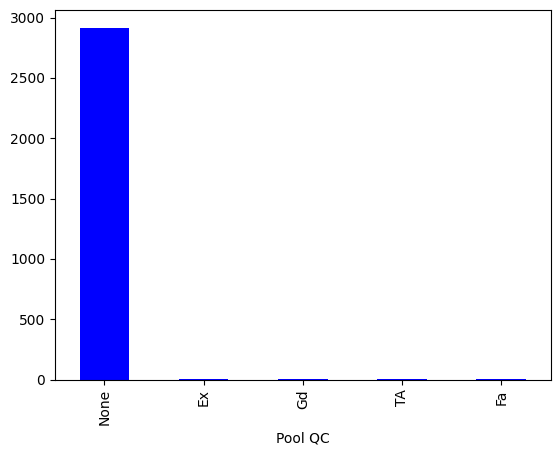

In [19]:
ah['Pool QC'] = ah['Pool QC'].fillna("None")

ah['Pool QC'].value_counts().plot(kind='bar', color='blue')

# we can observe that we have way too many missing values in 'Pool QC', so we will replace it with "Has_Pool"

ah["Has_Pool"] = (ah["Pool QC"] != "None").astype(int)

ah = ah.drop(columns=["Pool QC"])

# ah['Has_Pool'].value_counts().plot(kind='bar', color='blue')


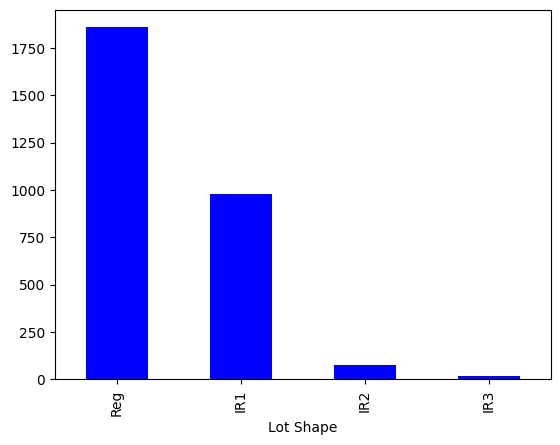

In [20]:
ah['Lot Shape'].value_counts().plot(kind='bar', color='blue')

# we will unify all irregular shapes in one category called "Irregular" and keep the regular shapes as they are

ah['Has_Irregular_Lot_Shape'] = ah['Lot Shape'].apply(lambda x: 1 if x in ['IR1', 'IR2', 'IR3'] else 0)
ah = ah.drop(columns=["Lot Shape"])

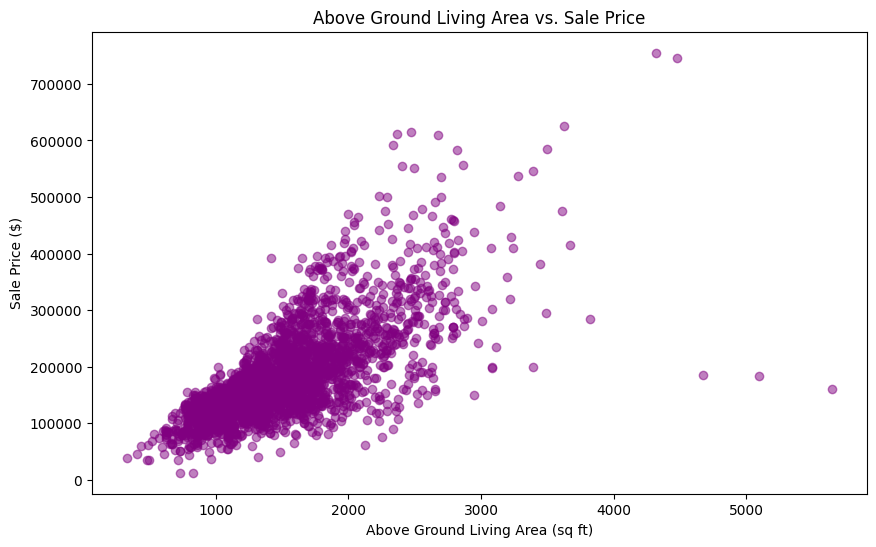

In [21]:
plt.figure(figsize=(10, 6))
plt.scatter(x=ah['Gr Liv Area'], y=ah['SalePrice'], alpha=0.5, color='purple')

plt.title('Above Ground Living Area vs. Sale Price')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')

plt.show()

# we see a trend between the above ground living area and the sale price, but there are some outliers that we will have to remove

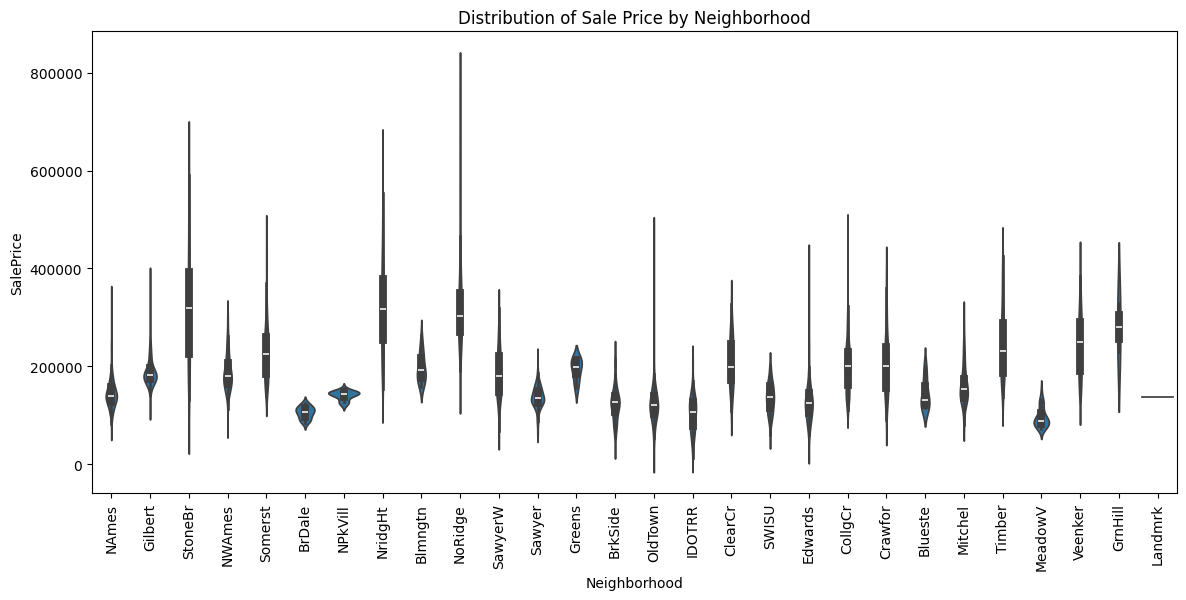

Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
NridgHt    166
Gilbert    165
Sawyer     151
NWAmes     131
SawyerW    125
Mitchel    114
BrkSide    108
Crawfor    103
IDOTRR      93
Timber      72
NoRidge     71
StoneBr     51
SWISU       48
ClearCr     44
MeadowV     37
BrDale      30
Blmngtn     28
Veenker     24
NPkVill     23
Blueste     10
Greens       8
GrnHill      2
Landmrk      1
Name: count, dtype: int64


In [22]:
plt.figure(figsize=(14, 6))
sns.violinplot(x='Neighborhood', y='SalePrice', data=ah)
plt.xticks(rotation=90)
plt.title('Distribution of Sale Price by Neighborhood')
plt.show()

print(ah['Neighborhood'].value_counts())

# We will replace "Neighborhood" with One Hot Encoding. We will split it into 3 categories: "Cheap", "Modest", "Expensive" based on the average sale price in each neighborhood.

# Some neighborhoods have a very diverse distribution, so we will remove outliers for a more accurate representation of the average sale price in each neighborhood

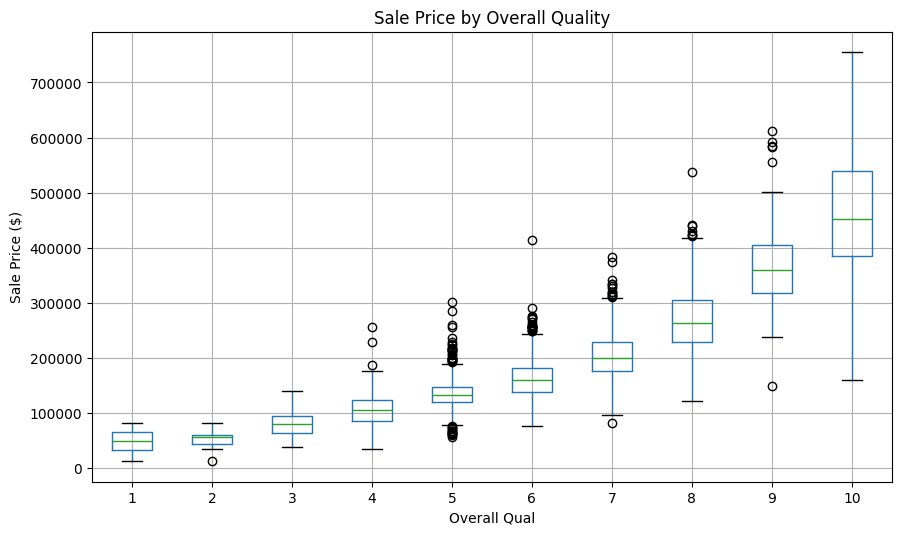

In [23]:
ah.boxplot(column='SalePrice', by='Overall Qual', figsize=(10, 6))
plt.title('Sale Price by Overall Quality')
plt.suptitle('')
plt.ylabel('Sale Price ($)')
plt.show()

# we can observe that "Overall Qual" is a highly reliable ordinal feature that has a strict positive correlation with  the sale price

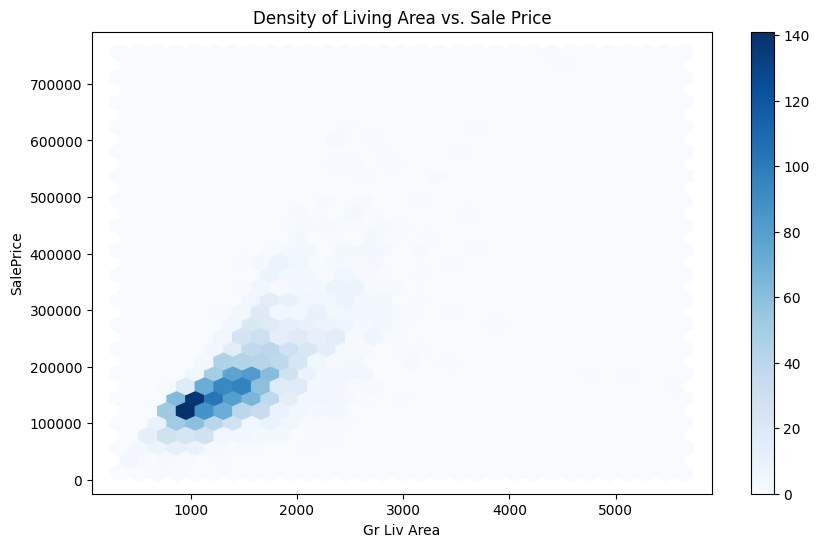

In [24]:
ah.plot(kind='hexbin', x='Gr Liv Area', y='SalePrice', gridsize=30, cmap='Blues', figsize=(10, 6))
plt.title('Density of Living Area vs. Sale Price')
plt.show()

# majority of the houses are concentrated in the lower left corner of the plot, meaning that most houses fit into the middle class category


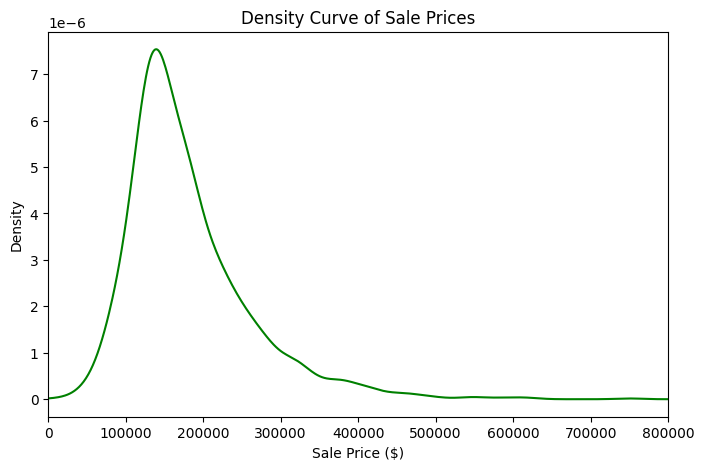

In [25]:
ah['SalePrice'].plot(kind='kde', figsize=(8, 5), color='green')
plt.title('Density Curve of Sale Prices')
plt.xlabel('Sale Price ($)')
plt.xlim(0, 800000) 
plt.show()

# we can observe that the sale price distribution is right-skewed

# we will apply a log transformation to the sale price to make it more normally distributed

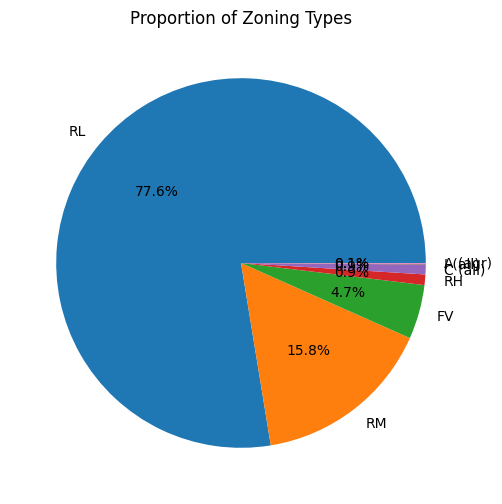

In [26]:
ah['MS Zoning'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6))
plt.title('Proportion of Zoning Types')
plt.ylabel('') 
plt.show()

# this category is dominated by "RL" (Residential Low Density). in this case we will replace this category "is_Residential_Low_Density"

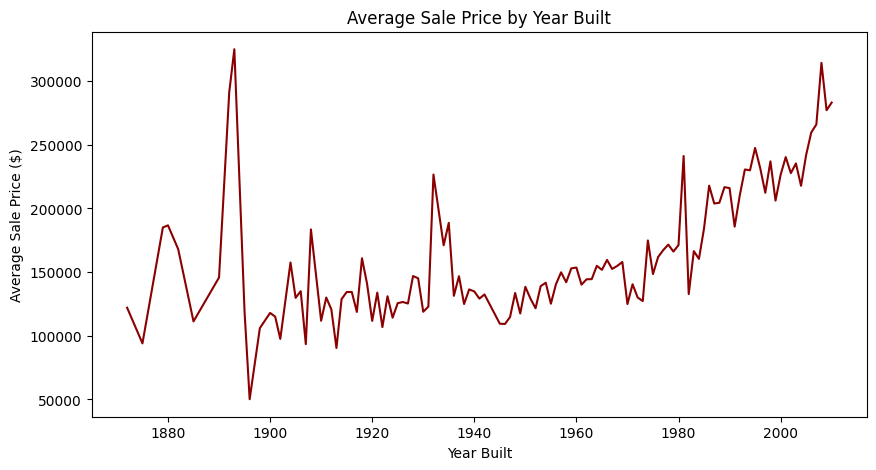

In [27]:
avg_price_by_year = ah.groupby('Year Built')['SalePrice'].mean()

avg_price_by_year.plot(kind='line', figsize=(10, 5), color='darkred')
plt.title('Average Sale Price by Year Built')
plt.ylabel('Average Sale Price ($)')
plt.show()

# not a huge correlation between the year built and the sale price, but we can see that houses built in the 2000s have a higher average sale price than older houses

# subtract Year Built from Yr Sold for a new feature called "House Age"

C:\Users\shoml\AppData\Local\Temp\ipykernel_35276\1844919994.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=ah, x='Bldg Type', palette='viridis')


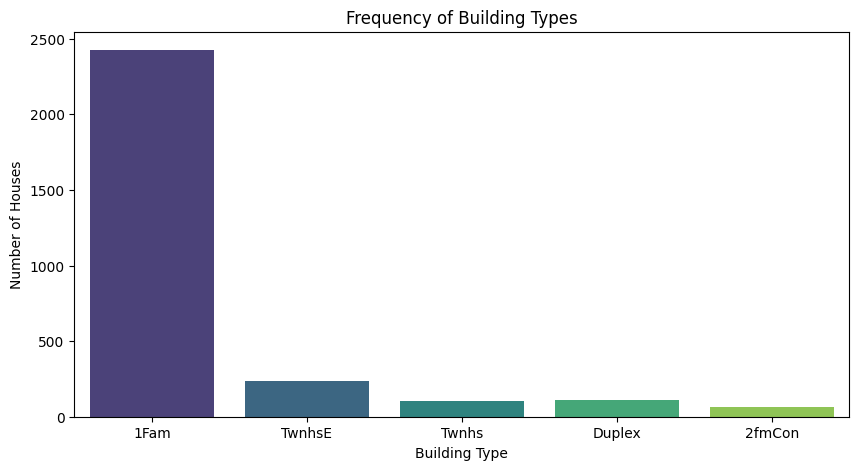

In [ ]:
plt.figure(figsize=(10, 5))
sns.countplot(data=ah, x='Bldg Type', palette='viridis')
plt.title('Frequency of Building Types')
plt.xlabel('Building Type')
plt.ylabel('Number of Houses')
plt.show()

# dataset is heavility skewed towards "1Fam". this means we will have to either replace it with a binary "is_1Fam" or delete it entirely

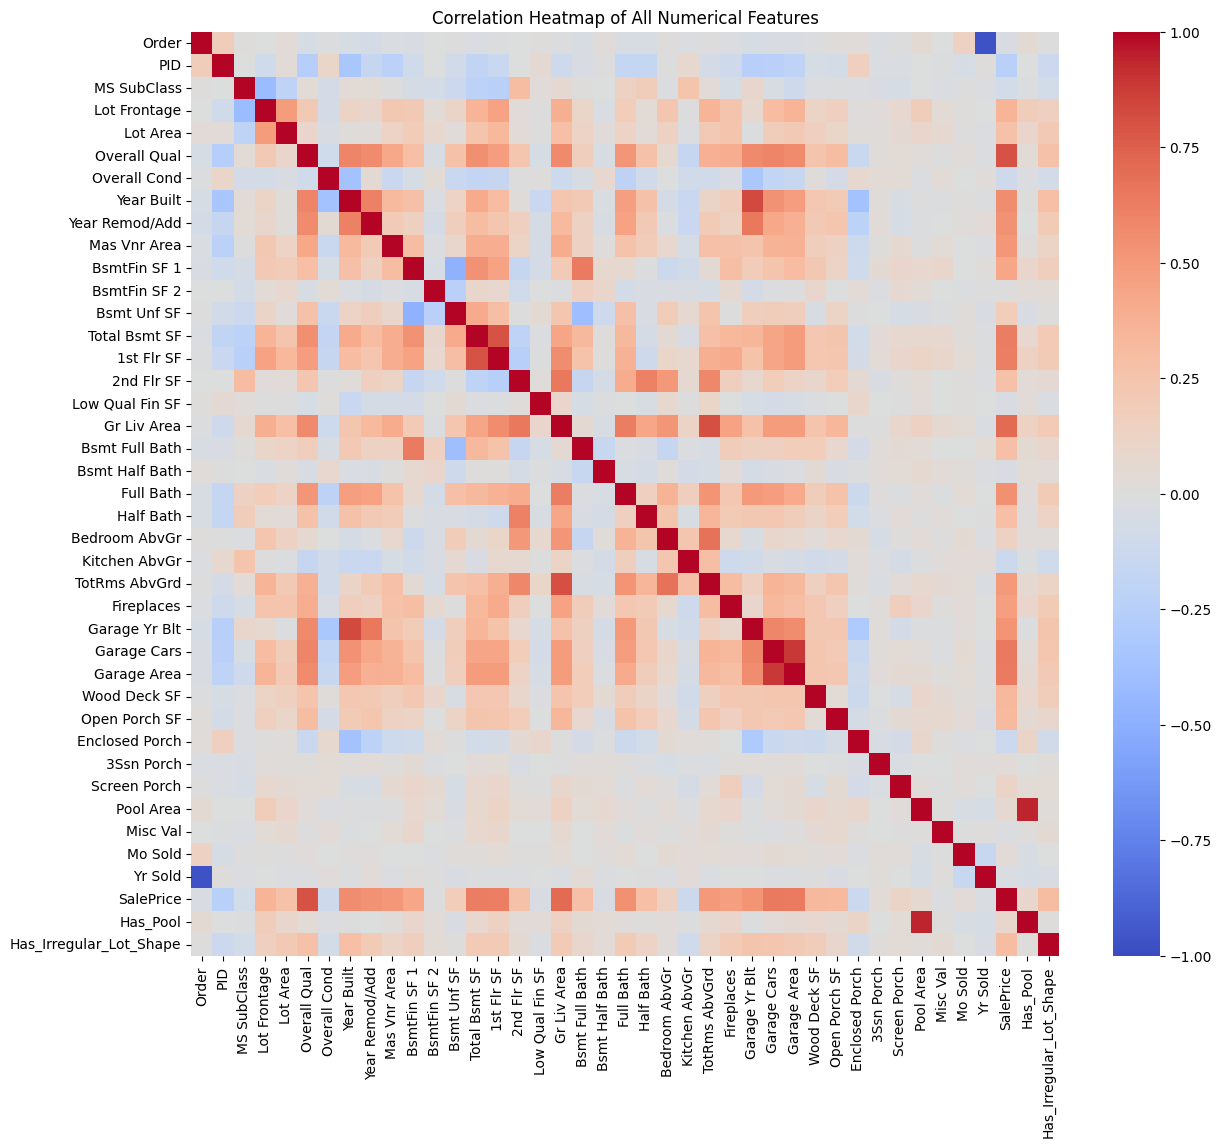

In [ ]:
numeric_ah = ah.select_dtypes(include=['int64', 'float64'])

corr_matrix = numeric_ah.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap of All Numerical Features')
plt.show()

# in this heatmap we can observe the correlation between various features. 

# for example, year built and garage year built are heavily correlated meaning that we can drop one of them (in this case garage year built)

In [32]:
from sklearn.linear_model import LinearRegression
import numpy as np

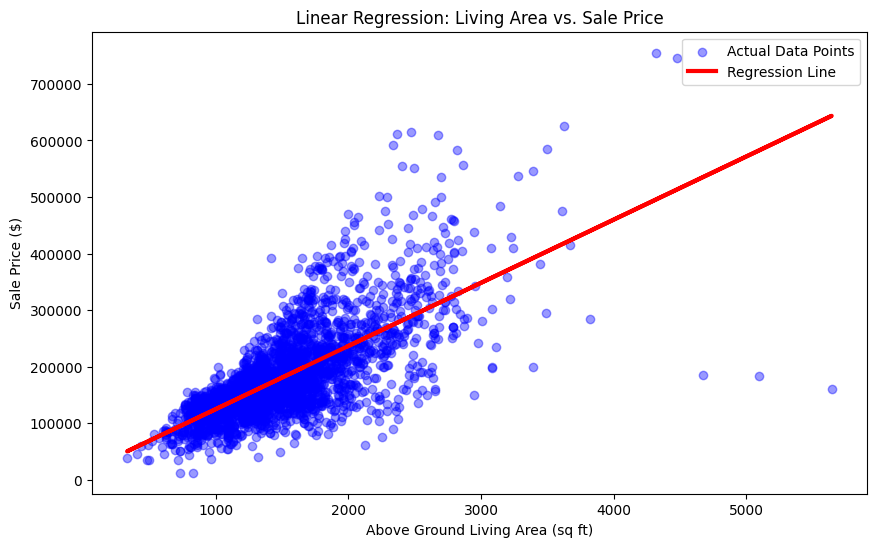

In [42]:
bonus_data = ah
X = bonus_data[['Gr Liv Area']] 
y = bonus_data['SalePrice']

model = LinearRegression()
model.fit(X, y)

y_line = model.predict(X)

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.4, label='Actual Data Points')
plt.plot(X, y_line, color='red', linewidth=3, label='Regression Line')
plt.title('Linear Regression: Living Area vs. Sale Price')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.legend()
plt.show()

In [43]:
actual_house1 = bonus_data[bonus_data['Gr Liv Area'] == 2000].iloc[0]
predicted_price = model.predict([[2000]])[0]

print(f"Dataset House (2000 sq ft) - Actual Price: ${actual_house1['SalePrice']}")
print(f"Dataset House (2000 sq ft) - Predicted Price: ${predicted_price:,.2f}")

custom_points = pd.DataFrame({'Gr Liv Area': [500, 3000]})
custom_predictions = model.predict(custom_points)

print(f"Custom Tiny Home (500 sq ft) - Predicted Price: ${custom_predictions[0]:,.2f}")
print(f"Custom Mansion (3000 sq ft) - Predicted Price: ${custom_predictions[1]:,.2f}")

Dataset House (2000 sq ft) - Actual Price: $305900
Dataset House (2000 sq ft) - Predicted Price: $236,677.64
Custom Tiny Home (500 sq ft) - Predicted Price: $69,136.63
Custom Mansion (3000 sq ft) - Predicted Price: $348,371.64


c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
# External data to enrich the model's predictions:
# Distance to the nearest school/university, noise level of the area, whether the area is a flood zone, school district rating

# possible features from combinations:

# subtract Year Built from Yr Sold for a new feature called "House Age"

# Merge baths and basement baths into a single feature called "Total Baths", the formula is below:
# Total Baths = Full Bath + 0.5 * Half Bath + Bsmt Full Bath + 0.5 * Bsmt Half Bath
# alternatively, we can just merge all rooms into "Total_Rooms, since number of bathrooms correlates well with number of bedrooms"

# we can also create a new feature called "Was_Remodeled". this feature will be dependent on if Year Remod/Add is different from Year Built.